# Бобина татьяна КомЗр24-1м
## Вариант 1
### Задача классификации

**Подготовка данных**

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                            f1_score, roc_auc_score, confusion_matrix,
                            ConfusionMatrixDisplay, roc_curve)
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [16]:
# Загрузка данных
data = pd.read_csv('/content/drive/MyDrive/Var no.1 (Class data).csv')
data

,client_id,Work\nPlace,Age,Marital\nStatus,Income,DIR,Num\nDependents,Num\nLoans,NumReal\nEstateLoans,BalanceTo\nCreditLimit,Num30_59\nDelinquencies,Num60_89\nDelinquencies,Delinq90\n_more,Unnamed: 13
0,59059,other,27.1,married,4323.0,0.018030,0.0,2.0,0,0.284997,0,0.0,-,NaN
1,29825,private-company,50.4,divorced,NaN,2017.844521,0.0,9.0,2,0.621962,0,0.0,-,NaN
2,22636,self-employed,68.2,married,3129.0,0.404992,1.0,2.0,0,1.019861,2,0.0,+,NaN
3,36739,private-company,67.1,single,13527.0,0.328576,1.0,15.0,2,0.635718,1,0.0,-,NaN
4,32216,self-employed,70.6,married,4273.0,0.082689,0.0,8.0,0,0.000000,0,0.0,-,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,17684,private-company,27.0,single,2513.0,0.088492,1.0,4.0,0,0.230910,0,0.0,-,NaN
4996,56363,private-company,56.1,married,13279.0,0.725305,2.0,11.0,4,0.284483,0,0.0,-,NaN
4997,71434,private-company,28.1,married,NaN,542.700838,0.0,12.0,0,0.546072,1,0.0,-,NaN
4998,64930,government-org,69.6,single,4023.0,0.227289,1.0,6.0,1,0.083983,0,0.0,-,NaN


In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   client_id               5000 non-null   int64  
 1   Work
Place              5000 non-null   object 
 2   Age                     5000 non-null   float64
 3   Marital
Status          5000 non-null   object 
 4   Income                  3988 non-null   float64
 5   DIR                     5000 non-null   float64
 6   Num
Dependents          4845 non-null   float64
 7   Num
Loans               4988 non-null   float64
 8   NumReal
EstateLoans     5000 non-null   int64  
 9   BalanceTo
CreditLimit   5000 non-null   float64
 10  Num30_59
Delinquencies  5000 non-null   int64  
 11  Num60_89
Delinquencies  4964 non-null   float64
 12  Delinq90
_more          4944 non-null   object 
 13  Unnamed: 13             0 non-null      float64
dtypes: float64(8), int64(3), object(3)
memor

In [18]:
# Проверка данных
print(data.head())
print(data.info())
print(data.describe())

   client_id      Work\nPlace   Age Marital\nStatus   Income          DIR  \
0      59059            other  27.1         married   4323.0     0.018030   
1      29825  private-company  50.4        divorced      NaN  2017.844521   
2      22636    self-employed  68.2         married   3129.0     0.404992   
3      36739  private-company  67.1          single  13527.0     0.328576   
4      32216    self-employed  70.6         married   4273.0     0.082689   

   Num\nDependents  Num\nLoans  NumReal\nEstateLoans  BalanceTo\nCreditLimit  \
0              0.0         2.0                     0                0.284997   
1              0.0         9.0                     2                0.621962   
2              1.0         2.0                     0                1.019861   
3              1.0        15.0                     2                0.635718   
4              0.0         8.0                     0                0.000000   

   Num30_59\nDelinquencies  Num60_89\nDelinquencies Deli

In [21]:
# 1. Проверим исходное распределение классов
print("Исходное распределение классов:")
print(data['Delinq90_more'].value_counts())

Исходное распределение классов:
Delinq90_more
0    4676
1     324
Name: count, dtype: int64


In [20]:
# Очистка названий столбцов (удаляем переносы строк)
data.columns = data.columns.str.replace('\n', '')
print("Очищенные названия столбцов:", data.columns.tolist())

# Удаление пустого столбца
if 'Unnamed: 13' in data.columns:
    data.drop('Unnamed: 13', axis=1, inplace=True)

# Проверка правильного названия целевого столбца
target_column = 'Delinq90_more'  # Используем очищенное название
print("\nУникальные значения в целевом столбце:", data[target_column].unique())

# Обработка целевой переменной
data[target_column] = data[target_column].apply(lambda x: 1 if x == '+' else 0)

# Разделение на признаки и целевую переменную
X = data.drop(target_column, axis=1)
y = data[target_column]

# Разделение на тренировочную и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
                                                   random_state=42,
                                                   stratify=y)

# Определение числовых и категориальных признаков
numeric_features = ['client_id', 'Age', 'Income', 'DIR', 'NumDependents',
                   'NumLoans', 'NumRealEstateLoans', 'BalanceToCreditLimit',
                   'Num30_59Delinquencies', 'Num60_89Delinquencies']

categorical_features = ['WorkPlace', 'MaritalStatus']

# Создание пайплайнов для обработки данных
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

# Объединение преобразователей
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)])

# Применение преобразований
print("\nНачало предобработки данных...")
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

print("\nПредобработка завершена успешно!")
print("Размерности данных:")
print("Обучающая выборка:", X_train_preprocessed.shape)
print("Тестовая выборка:", X_test_preprocessed.shape)
print("Целевая переменная (train):", y_train.shape)
print("Целевая переменная (test):", y_test.shape)

Очищенные названия столбцов: ['client_id', 'WorkPlace', 'Age', 'MaritalStatus', 'Income', 'DIR', 'NumDependents', 'NumLoans', 'NumRealEstateLoans', 'BalanceToCreditLimit', 'Num30_59Delinquencies', 'Num60_89Delinquencies', 'Delinq90_more', 'Unnamed: 13']

Уникальные значения в целевом столбце: ['-' '+' nan]

Начало предобработки данных...

Предобработка завершена успешно!
Размерности данных:
Обучающая выборка: (3500, 18)
Тестовая выборка: (1500, 18)
Целевая переменная (train): (3500,)
Целевая переменная (test): (1500,)


In [29]:
from sklearn.metrics import cohen_kappa_score

# 1. Проверка и балансировка данных
print("До балансировки:")
print("y_train:", np.unique(y_train, return_counts=True))
print("y_test:", np.unique(y_test, return_counts=True))

# Применение SMOTE для балансировки
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_preprocessed, y_train)

print("\nПосле балансировки:")
print("y_train_res:", np.unique(y_train_res, return_counts=True))

# 2. Обучение моделей на сбалансированных данных
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(50,25), max_iter=500, random_state=42)
}

results = []
for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train_res, y_train_res)
    y_pred = model.predict(X_test_preprocessed)
    y_prob = model.predict_proba(X_test_preprocessed)[:,1]

    # Расчет всех метрик
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, y_prob),
        'Kappa': cohen_kappa_score(y_test, y_pred)
    }
    results.append(metrics)

# 3. Анализ результатов
results_df = pd.DataFrame(results)
print("\nСравнение моделей:")
print(results_df.sort_values(by='ROC AUC', ascending=False))

# 4. Вывод лучшей модели с детальными метриками
best_model = results_df.loc[results_df['ROC AUC'].idxmax()]

print("\n" + "="*60)
print(f"ЛУЧШАЯ МОДЕЛЬ: {best_model['Model']}")
print("="*60)
print(f"Accuracy: {best_model['Accuracy']:.4f}")
print(f"Precision: {best_model['Precision']:.4f}")
print(f"Recall: {best_model['Recall']:.4f}")
print(f"F1 Score: {best_model['F1']:.4f}")
print(f"ROC-AUC: {best_model['ROC AUC']:.4f}")
print(f"Cohen's Kappa: {best_model['Kappa']:.4f}")
print("="*60)

До балансировки:
y_train: (array([0, 1]), array([3273,  227]))
y_test: (array([0, 1]), array([1403,   97]))

После балансировки:
y_train_res: (array([0, 1]), array([3273, 3273]))

Training Logistic Regression...

Training Decision Tree...

Training Random Forest...

Training Gradient Boosting...

Training Neural Network...

Сравнение моделей:
                 Model  Accuracy  Precision    Recall        F1   ROC AUC  \
2        Random Forest  0.921333   0.384615  0.360825  0.372340  0.799425   
3    Gradient Boosting  0.900667   0.300000  0.402062  0.343612  0.788810   
0  Logistic Regression  0.721333   0.147253  0.690722  0.242754  0.770029   
4       Neural Network  0.862667   0.177515  0.309278  0.225564  0.679913   
1        Decision Tree  0.856000   0.139394  0.237113  0.175573  0.567951   

      Kappa  
2  0.330423  
3  0.291106  
0  0.152393  
4  0.156231  
1  0.102468  

ЛУЧШАЯ МОДЕЛЬ: Random Forest
Accuracy: 0.9213
Precision: 0.3846
Recall: 0.3608
F1 Score: 0.3723
ROC-AUC: 0.

In [30]:
# Выбор лучшей модели
best_model_name = results_df.loc[results_df['ROC AUC'].idxmax(), 'Model']
best_model = models[best_model_name]

# Вывод информации о лучшей модели
print("\n\n=============================================")
print(f"Лучшая модель: {best_model_name}")
print("Ее показатели:")
best_metrics = results_df[results_df['Model'] == best_model_name].to_dict('records')[0]
for metric, value in best_metrics.items():
    if metric != 'Model':
        print(f"{metric}: {value:.4f}")
print("=============================================\n")



Лучшая модель: Random Forest
Ее показатели:
Accuracy: 0.9213
Precision: 0.3846
Recall: 0.3608
F1: 0.3723
ROC AUC: 0.7994
Kappa: 0.3304




Матрица ошибок для лучшей модели (Random Forest):


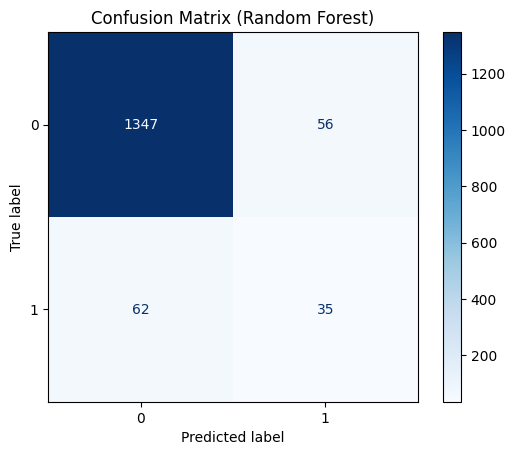

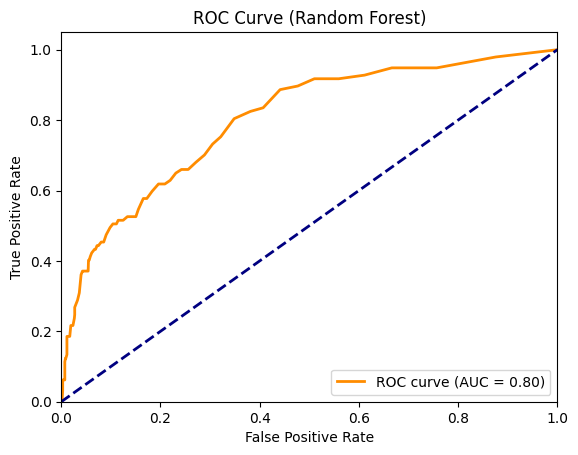

Оптимальный порог вероятности для Random Forest: 0.110


In [31]:
# Матрица ошибок для лучшей модели
print(f"\nМатрица ошибок для лучшей модели ({best_model_name}):")
y_pred_best = best_model.predict(X_test_preprocessed)
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title(f'Confusion Matrix ({best_model_name})')
plt.show()

# ROC-кривая для лучшей модели
y_prob_best = best_model.predict_proba(X_test_preprocessed)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob_best)
roc_auc = roc_auc_score(y_test, y_prob_best)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve ({best_model_name})')
plt.legend(loc="lower right")
plt.show()

# Оптимальный порог
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]
print(f"Оптимальный порог вероятности для {best_model_name}: {optimal_threshold:.3f}")